# 01 · Data Cleaning

**Project:** Hand Sign (ASL fingerspelling) Recognition  
**Dataset:** *ASL Fingerspelling Images (RGB & Depth)* — Pugeault & Bowden, "Spelling It Out" (Kaggle: `mrgeislinger/asl-rgb-depth-fingerspelling-spelling-it-out`)

The raw data is a collection of Kinect **colour** and **depth** frames, organised by *signer* and *letter*. It is not a table, so the usual
tabular cleaning checks are translated to their image-data equivalents:

| Classic check | What it means for this image dataset |
|---|---|
| Missing values | unreadable / corrupt files, missing labels, colour frames with no depth partner |
| Duplicates | byte-identical files (MD5) and visually identical frames (perceptual hash) |
| Outliers | blank/black/white frames, extremely blurry or noisy frames, tiny crops |
| Inconsistent formats | different image modes (RGB/RGBA/L/P), extensions and resolutions |

Every decision is logged, and the output is a **metadata table** (`data/interim/metadata_clean.csv`) that the next notebooks build on. Thresholds live in `src/config.py`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # make `src` importable when running from notebooks/
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, data_utils

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
config.IMAGES_DIR.mkdir(exist_ok=True); config.INTERIM_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.IMAGES_DIR / name, dpi=150, bbox_inches="tight"); print("saved images/" + name)

## 1. Locate and inventory the raw data
`locate_raw_data()` uses `data/raw/` (or `ASL_DATA_DIR`) if it already contains images, otherwise it downloads the dataset with `kagglehub`
(requires Kaggle credentials). `scan_files()` lists every image and parses **signer**, **letter** and **frame id** from the path — no pixels are read yet.

In [2]:
root = data_utils.locate_raw_data()
inv = data_utils.scan_files(root)
print("Raw data root:", root)
print("Total image files:", len(inv))
display(inv.groupby("kind").size().rename("files").to_frame())
display(inv.head())

Raw data root: C:\Users\5A_Traders\Desktop\pro\data\raw
Total image files: 131668


,files
kind,
color,65774
depth,65894


,path,rel_path,ext,size_bytes,kind,user,letter,frame
0,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0002.png,.png,26194,color,A,a,0_0002
1,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0003.png,.png,27343,color,A,a,0_0003
2,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0004.png,.png,26809,color,A,a,0_0004
3,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0005.png,.png,26075,color,A,a,0_0005
4,C:\Users\5A_Traders\Desktop\pro\data\raw\datas...,dataset5\A\a\color_0_0006.png,.png,27335,color,A,a,0_0006


## 2. Missing data: labels and colour/depth pairing
Only the **colour** images are used for the model (as in the existing system), but we still check that each colour frame has its depth partner,
and that every file sits in a valid letter folder (one of the 24 static letters; `j` and `z` need motion and are not in the dataset).

In [3]:
color = inv[inv.kind == "color"].copy()
depth_keys = set(map(tuple, inv.loc[inv.kind == "depth", ["user", "letter", "frame"]].values))
color["has_depth_pair"] = [(u, l, f) in depth_keys for u, l, f in color[["user", "letter", "frame"]].values]

print(f"Colour images: {len(color)}  |  without depth partner: {(~color.has_depth_pair).sum()}")
print("Files that are neither colour nor depth:", (inv.kind == "other").sum())
print("Unknown signer:", (color.user == "unknown").sum(), "| Unknown / invalid letter folder:", (~color.letter.isin(config.LETTERS)).sum())
print("Letters found:", "".join(sorted(color.letter.unique())))
print("Signers found:", sorted(color.user.unique()))

Colour images: 65774  |  without depth partner: 0
Files that are neither colour nor depth: 0
Unknown signer: 0 | Unknown / invalid letter folder: 0
Letters found: abcdefghiklmnopqrstuvwxy
Signers found: ['A', 'B', 'C', 'D', 'E']


## 3. Integrity and format consistency
Every colour image is opened and decoded. For each file we record the **format** (extension, mode, width, height) and quality features used later for outlier
detection (mean brightness, contrast, sharpness = variance of the Laplacian, mean R/G/B), plus an **MD5** and a **perceptual hash** for duplicate detection.

In [4]:
feats = data_utils.compute_features(color.path.tolist())
df = color.merge(feats, on="path", how="left")

print("Unreadable / corrupt files:", (~df.readable).sum())
if (~df.readable).any():
    display(df.loc[~df.readable, ["rel_path", "error"]].head(10))
ok = df[df.readable]
print("\nExtensions:"); display(ok.ext.value_counts().to_frame("files"))
print("Image modes:"); display(ok["mode"].value_counts().to_frame("files"))
print("Distinct resolutions:", ok.groupby(["width", "height"]).ngroups)
display(ok[["width", "height", "size_bytes"]].describe().T)

Unreadable / corrupt files: 0

Extensions:


,files
ext,
.png,65774


Image modes:


,files
mode,
RGB,65774


Distinct resolutions: 12660


,count,mean,std,min,25%,50%,75%,max
width,65774.0,103.169520,31.838720,64.0,78.0,93.0,123.0,249.0
height,65774.0,143.769103,23.951306,64.0,129.0,144.0,159.0,272.0
size_bytes,65774.0,29002.566911,9817.555955,7727.0,22121.0,26622.0,33771.0,103875.0


**Why this matters:** a CNN needs one fixed input shape and channel count. Mixed modes (e.g. RGBA or greyscale) and mixed resolutions are
therefore *standardised* in notebook 03 (convert to RGB, resize to 100×100) rather than dropped — only unreadable files are removed here.

## 4. Duplicates
* **Exact duplicates** — identical bytes (same MD5). Always removed.
* **Near duplicates** — identical perceptual hash *within the same signer and letter*. Frames come from a continuous Kinect recording, so consecutive frames can be
  almost identical. Keeping them inflates accuracy, because near-copies end up in both train and test. The first frame of each group is kept.

In [5]:
ok = df[df.readable].copy()
ok["dup_exact"] = ok.duplicated("md5", keep="first")
ok["dup_near"] = (~ok.dup_exact) & ok.duplicated(["user", "letter", "phash"], keep="first")
print("Exact duplicates:", ok.dup_exact.sum())
print("Near duplicates (same signer+letter, same perceptual hash):", ok.dup_near.sum())

# do identical files ever carry *different* labels? (label noise)
conflict = ok.groupby("md5").letter.nunique()
print("Identical images labelled as >1 letter (label conflicts):", (conflict > 1).sum())

Exact duplicates: 0
Near duplicates (same signer+letter, same perceptual hash): 2483
Identical images labelled as >1 letter (label conflicts): 0


## 5. Outliers
Two kinds of rules:
1. **Hard rules** — frames that are unusable regardless of the rest of the data: too small, almost black/white, or (near-)uniform with no contrast.
2. **Statistical rule** — sharpness (Laplacian variance) outside the **3 × IQR** fences. 3×IQR (instead of the usual 1.5×) flags only *extreme* values, because
   Kinect frames naturally vary in focus/noise and we do not want to throw away legitimate hard examples.

Brightness, contrast, width and height are also checked against the standard 1.5×IQR fences and **reported** (not dropped), since lighting variation between signers is real signal that the model must handle.

Sharpness fences (3xIQR): [-1428.6, 5128.2]


,lower_1p5IQR,upper_1p5IQR,n_outside_1p5IQR
feature,,,
width,10.50,190.50,791
height,84.00,204.00,1504
brightness,21.17,172.73,358
contrast,28.95,93.91,6
sharpness,-23.59,3723.13,382


too_small         0
bad_brightness    0
blank             0
sharp_outlier     0
saved images/01_outlier_boxplots.png


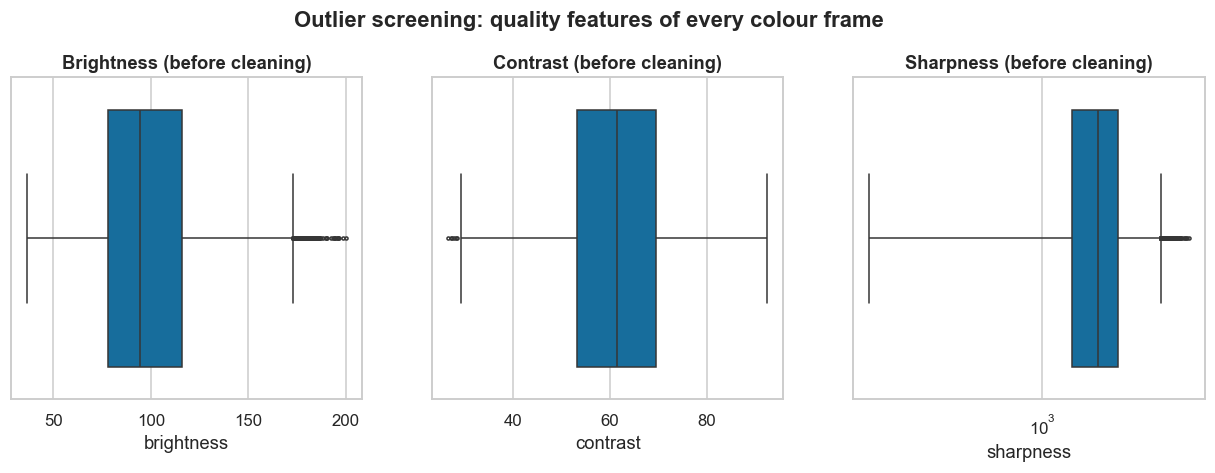

In [6]:
ok["too_small"] = (ok.width < config.MIN_SIDE_PX) | (ok.height < config.MIN_SIDE_PX)
ok["bad_brightness"] = (ok.brightness < config.MIN_MEAN_BRIGHTNESS) | (ok.brightness > config.MAX_MEAN_BRIGHTNESS)
ok["blank"] = ok.contrast < config.MIN_CONTRAST

lo, hi = data_utils.iqr_bounds(ok.sharpness, config.IQR_FACTOR)
ok["sharp_outlier"] = (ok.sharpness < lo) | (ok.sharpness > hi)
print(f"Sharpness fences (3xIQR): [{lo:.1f}, {hi:.1f}]")

rows = []
for col in ["width", "height", "brightness", "contrast", "sharpness"]:
    l, h = data_utils.iqr_bounds(ok[col], 1.5)
    rows.append(dict(feature=col, lower_1p5IQR=round(l, 2), upper_1p5IQR=round(h, 2),
                     n_outside_1p5IQR=int(((ok[col] < l) | (ok[col] > h)).sum())))
display(pd.DataFrame(rows).set_index("feature"))
print(ok[["too_small", "bad_brightness", "blank", "sharp_outlier"]].sum().to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
    sns.boxplot(x=ok[col], ax=ax, color=sns.color_palette()[0], fliersize=2)
    ax.set_title(f"{col.capitalize()} (before cleaning)")
    if col == "sharpness": ax.set_xscale("log")
fig.suptitle("Outlier screening: quality features of every colour frame", y=1.04, fontweight="bold")
save(fig, "01_outlier_boxplots.png")
plt.show()

**Reading the plot:** points far outside the box are the candidates for removal. Sharpness is plotted on a log scale because its values span orders of magnitude.

## 6. Apply the cleaning rules and log every decision
Each image is assigned **one** drop reason (first matching rule in the order below), so the log adds up exactly.

In [7]:
# also include files that could not be read (they have no features)
bad = df[~df.readable].copy()
bad["drop_reason"] = "unreadable"

ok["invalid_label"] = ~ok.letter.isin(config.LETTERS)
order = [("invalid_label", "invalid_label"), ("too_small", "too_small"), ("blank", "blank_frame"),
         ("bad_brightness", "extreme_brightness"), ("sharp_outlier", "sharpness_outlier"), ("dup_exact", "exact_duplicate")]
if config.DROP_NEAR_DUPLICATES:
    order.append(("dup_near", "near_duplicate"))

ok["drop_reason"] = ""
for col, reason in order:
    ok.loc[(ok.drop_reason == "") & ok[col], "drop_reason"] = reason

allmeta = pd.concat([ok, bad], ignore_index=True)
allmeta["keep"] = allmeta.drop_reason == ""

log = (allmeta.loc[~allmeta.keep, "drop_reason"].value_counts().rename_axis("reason").reset_index(name="images_removed"))
log.loc[len(log)] = ["TOTAL REMOVED", log.images_removed.sum()]
display(log)
print(f"Colour images before: {len(allmeta)}  ->  after: {allmeta.keep.sum()}  ({allmeta.keep.mean():.1%} kept)")

clean = allmeta[allmeta.keep].drop(columns=["keep", "drop_reason"]).reset_index(drop=True)
allmeta.to_csv(config.INTERIM_DIR / "metadata_all_with_flags.csv", index=False)
clean.to_csv(config.INTERIM_DIR / "metadata_clean.csv", index=False)
log.to_csv(config.INTERIM_DIR / "cleaning_log.csv", index=False)
print("Saved: data/interim/metadata_clean.csv, metadata_all_with_flags.csv, cleaning_log.csv")

,reason,images_removed
0,near_duplicate,2483
1,TOTAL REMOVED,2483


Colour images before: 65774  ->  after: 63291  (96.2% kept)
Saved: data/interim/metadata_clean.csv, metadata_all_with_flags.csv, cleaning_log.csv


saved images/01_class_counts_before_after.png


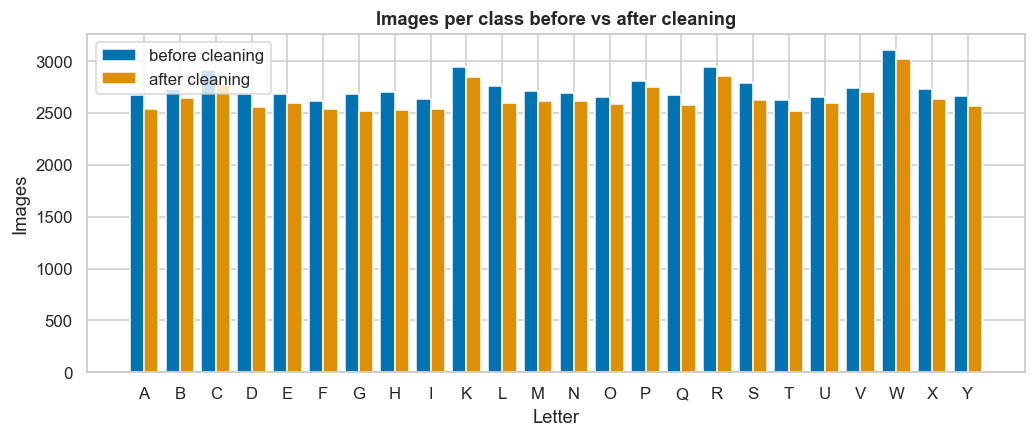

Smallest class after cleaning: T with 2516 images


In [8]:
before = allmeta.letter.value_counts().rename("before")
after = clean.letter.value_counts().rename("after")
cmp_ = pd.concat([before, after], axis=1).fillna(0).astype(int).sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(cmp_)); w = 0.4
ax.bar(x - w/2, cmp_.before, w, label="before cleaning", color=sns.color_palette()[0])
ax.bar(x + w/2, cmp_.after, w, label="after cleaning", color=sns.color_palette()[1])
ax.set_xticks(x); ax.set_xticklabels(cmp_.index.str.upper()); ax.set_xlabel("Letter"); ax.set_ylabel("Images")
ax.set_title("Images per class before vs after cleaning"); ax.legend()
save(fig, "01_class_counts_before_after.png"); plt.show()
print("Smallest class after cleaning:", cmp_.after.idxmin().upper(), "with", cmp_.after.min(), "images")

## Summary of cleaning
* **Missing / corrupt:** unreadable files and invalid labels are removed; colour frames without a depth partner are reported but kept (depth is not used).
* **Duplicates:** exact copies removed; near-identical consecutive frames within a signer+letter reduced to one.
* **Outliers:** blank, black/white, tiny and extreme-sharpness frames removed; milder lighting/size variation is kept on purpose.
* **Formats:** inconsistent modes/resolutions are not dropped — they are standardised in `03_preprocessing.ipynb`.

The numbers for these steps are in the tables above and in `data/interim/cleaning_log.csv`.